# Controller analysis: the linearized MPC

Everything `ControllerAnalysis_Estimator.ipynb` does, for the MPC with the linearized model (`MPCControllerLinearized` in `ControllerModels_Estimator.ipynb`):

1. **Loading** (fast: definitions only, no test plots)
2. **Step 1:** the model's equations against the plant
3. **Step 2:** the Jacobians $\mathbf{A}$, $\mathbf{B}$
4. **Step 3:** the 20 ms model $\mathbf{A}_j$, $\mathbf{B}_j$, $\mathbf{c}_j$ (20 sub-steps of 1 ms, Jacobians every 5 ms): 0.4 s predictions against the plant, and against Dana's simple model
5. **Step 4:** the MPC in Dana's runner: her benchmark, the test motions and her turning test, against PID and the simple MPC

The controllers: `'pid'` (Dana's), `'mpc'` (Dana's simple MPC, global velocity, Bryson weights), and the linearized MPC with three starting states: `'mpc_lin'` (measured and estimated every 20 ms), `'mpc_lin_obs'` (the 1 ms observer) and `'mpc_lin_true'` (the plant's true state, a test only). The MPCs share the same weights and limits (the Bryson block in the runner).

**Speed:** the linearized MPC takes about 9-10 ms per 20 ms step on this laptop (the `ms/step` column in the tables): the Jacobians at every 5 ms point of the plan in one batch, the relax rate $d$ every 1 ms, then Dana's QP. That is inside the 20 ms budget. This notebook uses a smaller set of paths than the main analysis file.


In [88]:
# Load only the definitions (no test plots): plant, parameters, controllers, path generator, Dana's runner
import json
import time
import numpy as np
import matplotlib.pyplot as plt


def notebook_cells(path):
    """The source of every cell of a notebook, in order."""
    with open(path, encoding="utf-8") as f:
        cells = json.load(f)["cells"]
    sources = ["".join(c["source"]) for c in cells]
    return sources


def notebook_cells_by_id(path):
    """The source of every cell of a notebook, by cell id."""
    with open(path, encoding="utf-8") as f:
        cells = json.load(f)["cells"]
    sources = {c.get("id"): "".join(c["source"]) for c in cells}
    return sources


# Plant: the observable state, both plant classes, the parameters, model_choice
plant_cells = notebook_cells_by_id("PlantModels.ipynb")
for cell_id in ("b5584b9d", "e4823acb", "ce831979", "f56abec6", "bf71ff62"):
    exec(plant_cells[cell_id])

# Controllers: every code cell of the models notebook (Dana's PID and MPC, the linearized model and MPC)
for source in notebook_cells("ControllerModels_Estimator.ipynb"):
    if source.lstrip().startswith(("import", "class")):
        exec(source)

# Path generator (Dana's class only, not her demo plots)
for source in notebook_cells("PathGeneration.ipynb"):
    if "class PathGenerator" in source:
        exec(source)

# Dana's timer (from the main analysis notebook). The runner is in the next cell: Dana's, with the linearized MPC added.
for source in notebook_cells("ControllerAnalysis_Estimator.ipynb"):
    if "class CodeTimer" in source:
        exec(source)

controller_colors = {'pid': 'royalblue', 'mpc': 'darkorange', 'mpc_lin': 'seagreen', 'mpc_lin_obs': 'crimson', 'mpc_lin_true': 'purple'}
print("Loaded: plant, parameters, PID, simple MPC, linearized model and MPC, path generator, runner")


Loaded: plant, parameters, PID, simple MPC, linearized model and MPC, path generator, runner


## Dana's runner, with the linearized MPC

A copy of `execute_simulation` from `ControllerAnalysis_Estimator.ipynb` (Dana's, with the Bryson weights), with the linearized MPC added: `'mpc_lin'`, `'mpc_lin_obs'` and `'mpc_lin_true'` set its `state_estimate` to `'pose'`, `'observer'` and `'true'`. For `'mpc_lin_obs'` the runner feeds the observer every plant step (`estimator_update`), with the camera pose at the end of each 20 ms controller step.

In [89]:
# paramaters and classed are defined in xxxx.ipynb and imported above, so we need to declare them as global to avoid "undefined variable" errors
global model_choice, simulation_parameters, PathGenerator
global OmniRobotSimulationExplicit, OmniRobotStateExplicit, OmniRobotSimulationODESolve, OmniRobotStateODESolve
global CascadedPIDController, MPCControllerSimple



def execute_simulation(plant_parm:dict, controller_type: str, ref_path:dict) -> dict:
    """Executes closed-loop simulation for either PID or MPC over duration T."""
    
    if model_choice == 1:
        plant = OmniRobotSimulationExplicit(dict(plant_parm, lugre_deflection=100e-6), random_seed=42)   # ADDED: 100 um bristle (2 um is too stiff for the explicit plant)
        plant_state = OmniRobotStateExplicit()  
        observable_state = plant.get_observable_state(plant_state)  
    elif model_choice == 2:   
        plant = OmniRobotSimulationODESolve(plant_parm, random_seed=42)
        plant_state = OmniRobotStateODESolve()
        observable_state = plant.get_observable_state(plant_state)
    
    # =======================================================================
    # ADDED: MPC weights from Bryson's rule, weight = 1 / (largest acceptable value)^2
    # (Dana's were q_pose=(100, 100, 60), q_vel=(15, 15, 8), r_voltage=0.015, r_slew=0.008)
    # =======================================================================
    wheelbase_radius = plant_parm['Rb']  # wheel distance from the centre: turns a heading error into a distance at the wheels
    max_pos_err = 0.05                   # acceptable position error (m)
    max_heading_err = np.radians(5.0)    # ADDED: acceptable heading error (rad). Before: max_pos_err / wheelbase_radius (~36 deg),
                                         # so the MPC let heading drift 20 deg to save position
    max_vel_err = 0.10                   # acceptable velocity error (m/s)
    max_dV = 0.5                         # acceptable CHANGE in voltage per 20 ms step (V): the main voltage cost
    max_V = 6.0                          # acceptable voltage (V): a light cost on the voltage itself. It keeps the MPC from
                                         # driving the wheels into slip, which its model (no friction) cannot predict.
                                         # None = no cost on the voltage, only on its change.

    q_pose_bryson = (1 / max_pos_err**2, 1 / max_pos_err**2, 1 / max_heading_err**2)      # x, y, heading
    q_vel_bryson = (1 / max_vel_err**2, 1 / max_vel_err**2, 1 / (max_vel_err / wheelbase_radius)**2)       # x_dot, y_dot, yaw rate
    r_slew_bryson = 1 / max_dV**2                                                                          # cost on (V_j - V_j-1)^2
    r_voltage_bryson = 0.0 if max_V is None else 1 / max_V**2                                              # cost on V_j^2

    if controller_type.lower() == 'pid':
        ctrl = CascadedPIDController(
            plant_parm,
            pos_pid_gains={'kp': 1.5, 'ki': 0.1, 'kd': 0.05},
            wheel_pid_gains={'kp': 0.15, 'ki': 0.8, 'kd': 0.0},
            dt=0.02, a_max=3.5, alpha_max=7.0, 
            k_theta=3.0, voltage_limit=12.0
        )
    elif controller_type.lower() in ('mpc_lin', 'mpc_lin_true', 'mpc_lin_obs'):
        # ADDED: Dana's MPC with the linearized model (same weights and limits). Where its starting state comes from:
        # 'mpc_lin' measured and estimated every 20 ms, 'mpc_lin_obs' the 1 ms observer, 'mpc_lin_true' the plant's true
        # state (a test)
        state_estimate = {'mpc_lin': 'pose', 'mpc_lin_obs': 'observer', 'mpc_lin_true': 'true'}[controller_type.lower()]
        ctrl = MPCControllerLinearized(
            plant_parm, state_estimate=state_estimate,
            horizon_K=8, dt=0.02,
            q_pose=q_pose_bryson, q_vel=q_vel_bryson,
            r_voltage=r_voltage_bryson, r_slew=r_slew_bryson,
            voltage_limit=12.0, current_limit = 20.0, delta_v_max=5.0
            )
    elif controller_type.lower() == 'mpc_no_vel':
        # ADDED: the same MPC with no velocity term in the stage cost (Dana's idea), q_vel = 0
        ctrl = MPCControllerSimple(
            plant_parm, horizon_K=8, dt=0.02,
            q_pose=q_pose_bryson, q_vel=(0.0, 0.0, 0.0),
            r_voltage=r_voltage_bryson, r_slew=r_slew_bryson,
            voltage_limit=12.0, current_limit = 20.0, delta_v_max=5.0
            )
    else:
        ctrl = MPCControllerSimple(
            plant_parm, horizon_K=8, dt=0.02,
            q_pose=q_pose_bryson, q_vel=q_vel_bryson,                  # ADDED: Bryson weights above
            r_voltage=r_voltage_bryson, r_slew=r_slew_bryson,          # ADDED: Bryson weights above
            voltage_limit=12.0, current_limit = 20.0, delta_v_max=5.0
            )

    # Extract reference trajectory data
    t_ref = ref_path['t']
    pos_ref = ref_path['pos']
    vel_ref = ref_path['vel']
    N = len(t_ref)
    duration = t_ref[-1] - t_ref[0]
    
    # Precompute local reference velocity vectors (logged only)
    # GLOBAL FRAME: with the plant's rotation. The MPC is given the GLOBAL reference vel_ref (its velocity state is global).
    V_local_ref = np.zeros_like(vel_ref)
    for i in range(N):
        V_local_ref[i] = OmniRobotSimulationODESolve._rotation(pos_ref[i, 2]).T @ vel_ref[i]

    # Initialize logging arrays   
    log_pos = []
    log_v = []
    log_V = []
    log_vs = []
    log_opt = []
    
    dt_ctrl = ctrl.dt
    substeps = int(round(dt_ctrl / plant_parm['dt'])) # holding substeps

    timer = CodeTimer()
    timer.start()
    for k in range(N):
        # ADDED NOTE: the controller gets the robot's current pose with no delay, as if a 1 ms estimator supplied it.
        # On the robot the camera is ~60 Hz and ~50 ms late; a Kalman filter replaying the 1 ms sensor data would be needed.
        observable_state = plant.get_observable_state(plant_state)
        
        p_d = pos_ref[k]
        v_d = vel_ref[k]
        
        if controller_type.lower() == 'pid':
            u = ctrl.compute(p_d, observable_state)
            is_opt = True
        else:
            if k + ctrl.K + 1 <= N:
                p_h = pos_ref[k : k + ctrl.K + 1]
                v_h = vel_ref[k : k + ctrl.K + 1]            # GLOBAL FRAME: global velocity reference
            else:
                pad = (k + ctrl.K + 1) - N
                p_h = np.vstack([pos_ref[k:], np.tile(pos_ref[-1], (pad, 1))])
                v_h = np.vstack([vel_ref[k:], np.zeros((pad, 3))])   # GLOBAL FRAME: global velocity reference
            if controller_type.lower() == 'mpc_lin_true':
                ctrl.true_state = plant_state     # ADDED: the test gets the plant's true state
            u, info = ctrl.compute_optimal_u0(measured_State=observable_state, path_ref_horizon=p_h, vel_ref_horizon=v_h, return_info=True)
            is_opt = info['optimal']

        #loop through the substeps to integrate the plant dynamics
        timer.pause()
        for substep in range(substeps):
            plant_state = plant.step(plant_state, u)
            if controller_type.lower() == 'mpc_lin_obs':
                # ADDED: the 1 ms observer (its own core, not timed): wheel speeds and currents every plant step,
                # the camera pose at the end of each 20 ms controller step
                ctrl.estimator_update(plant.get_observable_state(plant_state), camera_frame=(substep == substeps - 1))

        
        # calculate data from plant_state and observable_state
        v_contact = plant.H @ plant_state.v_local
        v_s = v_contact - plant.p['r'] * plant_state.omega

        # log data for analysis  
        log_pos.append(plant_state.pos_global.copy())
        log_v.append(plant_state.v_global.copy())
        log_V.append(u.copy())
        log_vs.append(v_s.copy())
        log_opt.append(is_opt)
        timer.resume()

    timer.pause()    
    elapsed = timer.elapsed
    log_pos = np.array(log_pos)
    log_v = np.array(log_v)
    log_V = np.array(log_V)
    log_vs = np.array(log_vs)
    log_opt = np.array(log_opt)
    
    dist_err = np.hypot(pos_ref[:, 0] - log_pos[:, 0], pos_ref[:, 1] - log_pos[:, 1])
    th_err = np.abs((pos_ref[:, 2] - log_pos[:, 2] + np.pi) % (2.0 * np.pi) - np.pi)
    
    return {
        'type': controller_type.upper(), 'duration': duration,
        't': t_ref, 'pos_ref': pos_ref, 'vel_ref': vel_ref, 'V_local_ref': V_local_ref,
        'pos': log_pos, 'v': log_v, 'V': log_V, 'vs': log_vs,
        'dist_err': dist_err, 'th_err': th_err, 'log_opt': log_opt,
        'elapsed': elapsed
    }




## Step 1 check: does $f$ agree with the plant?

In [90]:
# Step 1 check: f at the plant's new state against the plant's own 1 ms step
# defined in the notebooks loaded with %run above; declared global so the editor sees them (as Dana does)
global simulation_parameters, OmniRobotSimulationODESolve, OmniRobotStateODESolve, OmniRobotLinearizedModel
check_params = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0, implicit_tol=1e-12, implicit_max_iter=200)
model = OmniRobotLinearizedModel(check_params)
plant = OmniRobotSimulationODESolve(check_params)
state = OmniRobotStateODESolve()
dt = check_params['dt']
V_strafe = np.array([-6.0, -6.0, 6.0, 6.0])

names = ["pose", "velocity", "currents", "wheel speeds", "bristles"]
parts = [model.POSE, model.VELOCITY, model.CURRENTS, model.WHEELS, model.BRISTLES]
worst_gap = np.zeros(5)
worst_matched = np.zeros(5)
largest_rate = np.zeros(5)
sliding_steps = 0
worst_load_gap = 0.0

for k in range(1000):
    V = V_strafe if k < 500 else -V_strafe            # reverse at 0.5 s so the wheels slide
    F_n = plant.compute_dynamic_normal_forces(state)  # the loads the plant uses this step (no noise)
    x_now = model.get_state_from_plant(state)
    state = plant.step(state, V)
    x_next = model.get_state_from_plant(state)
    plant_rate = (x_next - x_now) / dt

    # (a) f at the plant's new state, as it is
    bristle_decay = model.get_bristle_decay(x_next)
    model_rate = model.get_state_derivative(x_next, V, bristle_decay, F_n=F_n)

    # (b) f given the start-of-step values the plant uses in those terms
    matched_rate = model_rate.copy()
    #   velocity row: the forces rotated with the OLD heading (plant: R_theta at the step start), and the roller
    #   friction from the OLD velocity (plant: compute_roller_friction uses state.v_local at the step start)
    x_old_heading = x_next.copy()
    x_old_heading[2] = x_now[2]
    x_old_heading[model.VELOCITY] = x_now[model.VELOCITY]
    matched_rate[model.VELOCITY] = model.get_state_derivative(x_old_heading, V, bristle_decay, F_n=F_n)[model.VELOCITY]
    #   bristle row: the slip with the OLD velocity and heading (plant: v_center_d = H_drive v_local at the step start)
    x_old_velocity = x_next.copy()
    x_old_velocity[2] = x_now[2]
    x_old_velocity[model.VELOCITY] = x_now[model.VELOCITY]
    bristle_decay_old_v = model.get_bristle_decay(x_old_velocity)
    matched_rate[model.BRISTLES] = model.get_state_derivative(x_old_velocity, V, bristle_decay_old_v, F_n=F_n)[model.BRISTLES]
    #   wheel row: the rolling drag with the OLD wheel speed (plant: T_roll from state.omega at the step start)
    T_roll_old = check_params['Crr'] * F_n * check_params['r'] * np.tanh(x_now[model.WHEELS] / check_params['roll_smoothing'])
    F_floor_next = -check_params['mu_s'] * F_n * x_next[model.BRISTLES]
    matched_rate[model.WHEELS] = (check_params['Kt'] * x_next[model.CURRENTS] - T_roll_old - check_params['r'] * F_floor_next) / check_params['Jw']

    for n, part in enumerate(parts):
        worst_gap[n] = max(worst_gap[n], np.max(np.abs(model_rate[part] - plant_rate[part])))
        worst_matched[n] = max(worst_matched[n], np.max(np.abs(matched_rate[part] - plant_rate[part])))
        largest_rate[n] = max(largest_rate[n], np.max(np.abs(plant_rate[part])))
    sliding_steps += np.any(state.S)
    worst_load_gap = max(worst_load_gap, np.max(np.abs(model.get_wheel_loads(x_now) - F_n)))    # model's loads vs the plant's, same step

print(f"1000 plant steps, {sliding_steps} with a wheel sliding")
print(f"{'state':14s} {'largest rate':>13s} | {'(a) gap':>10s} {'/ rate':>9s} | {'(b) gap':>10s} {'/ rate':>9s}")
for n in range(5):
    print(f"{names[n]:14s} {largest_rate[n]:13.4g} | {worst_gap[n]:10.3g} {worst_gap[n] / largest_rate[n]:9.1e} | "
          f"{worst_matched[n]:10.3g} {worst_matched[n] / largest_rate[n]:9.1e}")
print(f"wheel loads: the model's (from its lagged acceleration state) vs the plant's, same step: largest gap {worst_load_gap:.3g} N")


1000 plant steps, 999 with a wheel sliding
state           largest rate |    (a) gap    / rate |    (b) gap    / rate
pose                   4.771 |   2.22e-13   4.7e-14 |   2.22e-13   4.7e-14
velocity               220.7 |      0.329   1.5e-03 |   4.43e-13   2.0e-15
currents                2596 |   1.42e-12   5.5e-16 |   1.42e-12   5.5e-16
wheel speeds            5939 |       89.7   1.5e-02 |   2.27e-10   3.8e-14
bristles                1861 |   4.04e+03   2.2e+00 |   4.09e-06   2.2e-09
wheel loads: the model's (from its lagged acceleration state) vs the plant's, same step: largest gap 1.78e-15 N


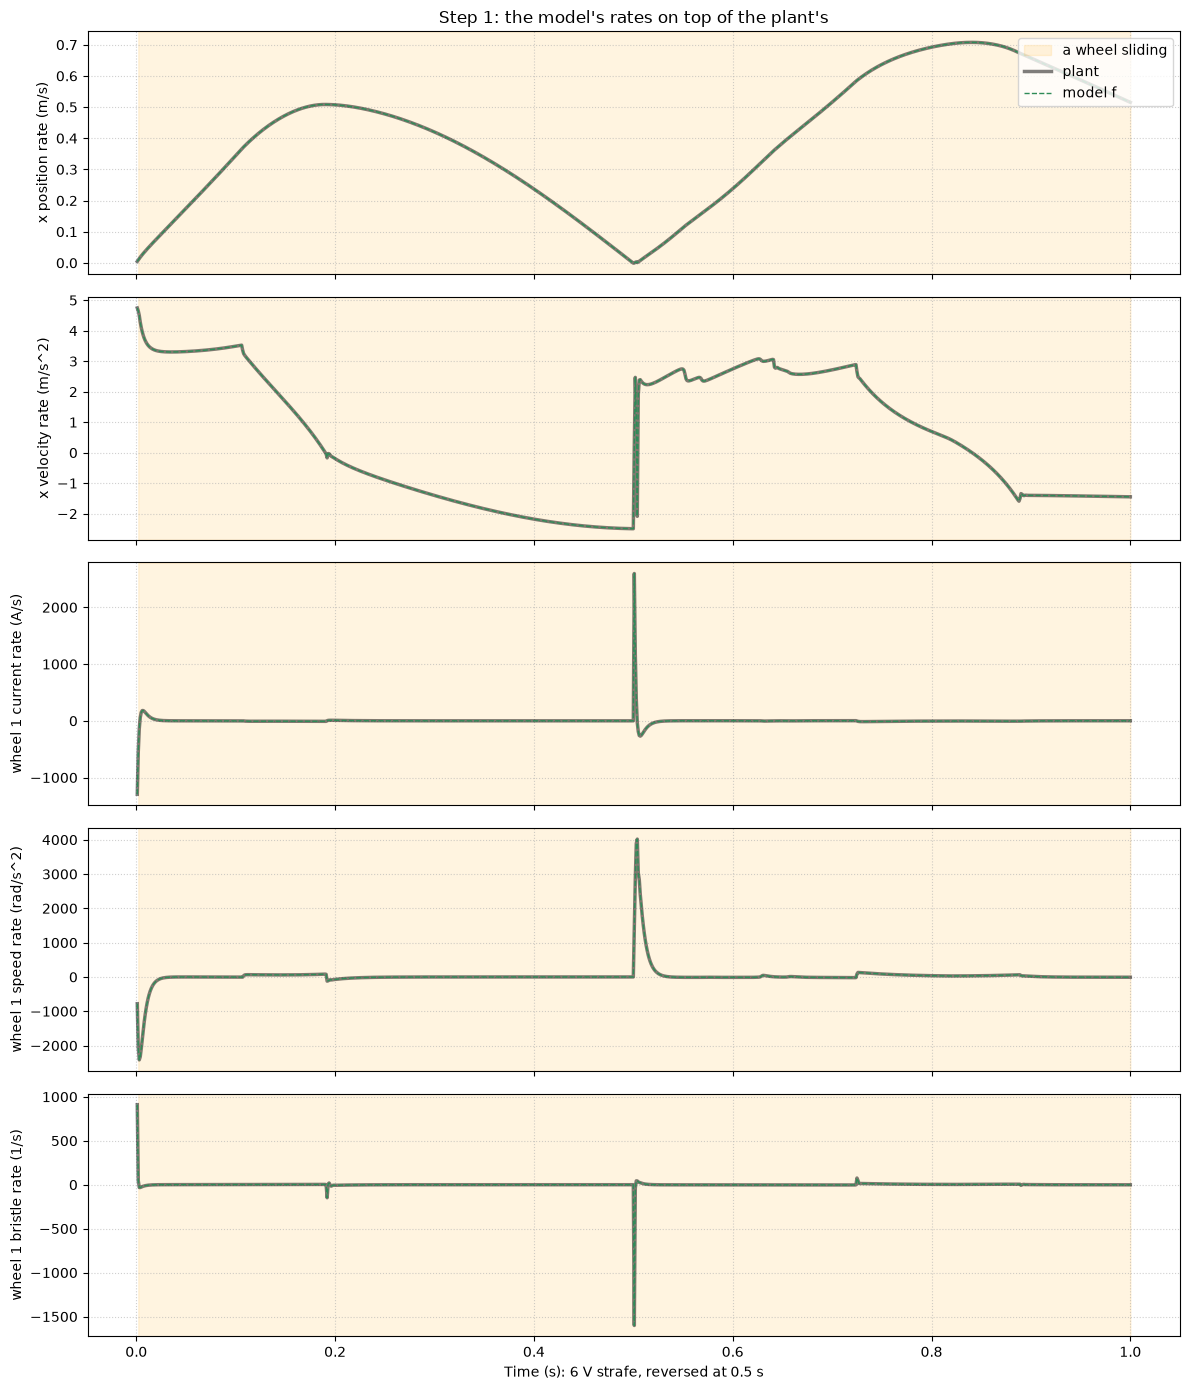

In [91]:
# Step 1 plot: one rate from each part of the state, plant against model (with the plant's start-of-step values)
plot_params = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0, implicit_tol=1e-12, implicit_max_iter=200)
model = OmniRobotLinearizedModel(plot_params)
plant = OmniRobotSimulationODESolve(plot_params)
state = OmniRobotStateODESolve()
dt = plot_params['dt']
V_strafe = np.array([-6.0, -6.0, 6.0, 6.0])
rows = [("x position rate (m/s)", 0), ("x velocity rate (m/s^2)", 3), ("wheel 1 current rate (A/s)", 6),
        ("wheel 1 speed rate (rad/s^2)", 10), ("wheel 1 bristle rate (1/s)", 14)]
plant_series, model_series, sliding = [], [], []
for k in range(1000):
    V = V_strafe if k < 500 else -V_strafe
    F_n = plant.compute_dynamic_normal_forces(state)
    x_now = model.get_state_from_plant(state)
    state = plant.step(state, V)
    x_next = model.get_state_from_plant(state)
    plant_rate = (x_next - x_now) / dt
    # the model's rate, given the plant's start-of-step values in the terms where the plant uses them
    x_matched = x_next.copy()
    x_matched[2] = x_now[2]
    x_matched[model.VELOCITY] = x_now[model.VELOCITY]
    d_matched = model.get_bristle_decay(x_matched)
    rate = model.get_state_derivative(x_next, V, d_matched, F_n=F_n)
    rate[model.VELOCITY] = model.get_state_derivative(x_matched, V, d_matched, F_n=F_n)[model.VELOCITY]
    rate[model.BRISTLES] = model.get_state_derivative(x_matched, V, d_matched, F_n=F_n)[model.BRISTLES]
    T_roll_old = plot_params['Crr'] * F_n * plot_params['r'] * np.tanh(x_now[model.WHEELS] / plot_params['roll_smoothing'])
    rate[model.WHEELS] = (plot_params['Kt'] * x_next[model.CURRENTS] - T_roll_old + plot_params['r'] * plot_params['mu_s'] * F_n * x_next[model.BRISTLES]) / plot_params['Jw']
    plant_series.append([plant_rate[i] for _, i in rows])
    model_series.append([rate[i] for _, i in rows])
    sliding.append(np.any(state.S))
plant_series, model_series, sliding = np.array(plant_series), np.array(model_series), np.array(sliding)
t = dt * np.arange(1, 1001)

fig, axs = plt.subplots(len(rows), 1, figsize=(12, 14), sharex=True)
for n, (label, _) in enumerate(rows):
    axs[n].fill_between(t, 0, 1, where=sliding, color='orange', alpha=0.12, transform=axs[n].get_xaxis_transform(), label='a wheel sliding')
    axs[n].plot(t, plant_series[:, n], color='black', lw=2.5, alpha=0.5, label='plant')
    axs[n].plot(t, model_series[:, n], color='seagreen', lw=1.0, ls='--', label='model f')
    axs[n].set_ylabel(label); axs[n].grid(True, linestyle=':', alpha=0.6)
axs[0].legend(loc='upper right'); axs[-1].set_xlabel("Time (s): 6 V strafe, reversed at 0.5 s")
axs[0].set_title("Step 1: the model's rates on top of the plant's")
plt.tight_layout()
plt.show()


## Step 2 check: the Jacobians

In [92]:
# Step 2 check: the Jacobians against entries worked out by hand, and against small changes in f
# defined in the notebooks loaded with %run above; declared global so the editor sees them (as Dana does)
global simulation_parameters, OmniRobotSimulationODESolve, OmniRobotStateODESolve, OmniRobotLinearizedModel
check_params = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
model = OmniRobotLinearizedModel(check_params)
plant = OmniRobotSimulationODESolve(check_params)
state = OmniRobotStateODESolve()
V_strafe = np.array([-6.0, -6.0, 6.0, 6.0])

# Run the plant and keep two points: gripping (0.30 s, before the reversal) and sliding (0.55 s, just after it)
points = {}
for k in range(600):
    V = V_strafe if k < 500 else -V_strafe
    state = plant.step(state, V)
    if k == 299:
        points['gripping'] = (model.get_state_from_plant(state), V.copy(), state.a_local_past.copy(), state.S.copy())
    if k == 549:
        points['sliding'] = (model.get_state_from_plant(state), V.copy(), state.a_local_past.copy(), state.S.copy())

p = check_params
rng = np.random.default_rng(0)
for name, (x, u, a_local_past, sliding_flags) in points.items():
    bristle_decay = model.get_bristle_decay(x)
    F_n = model.get_wheel_loads(x)
    A, B = model.get_continuous_matrices(x, u, bristle_decay, F_n=F_n)          # (a): loads held, so the hand formulas are exact
    A_full, B_full = model.get_continuous_matrices(x, u, bristle_decay)         # (b): the model as the MPC uses it, loads differentiated

    # (a) entries worked out by hand, wheel 1 (index 0)
    hand = [
        ("d(pose rate)/d(velocity), x", A[0, 3], 1.0),
        ("d(I_dot)/dV = 1/Lm", B[6, 0], 1.0 / p['Lm']),
        ("d(I_dot)/dI = -R/Lm", A[6, 6], -p['R'] / p['Lm']),
        ("d(I_dot)/d(omega) = -Kb/Lm", A[6, 10], -p['Kb'] / p['Lm']),
        ("d(omega_dot)/dI = Kt/Jw", A[10, 6], p['Kt'] / p['Jw']),
        ("d(omega_dot)/dz = r mu_s F_n/Jw", A[10, 14], p['r'] * p['mu_s'] * F_n[0] / p['Jw']),
        ("d(z_dot)/d(omega) = -r/delta", A[14, 10], -p['r'] / p['lugre_deflection']),
        ("d(z_dot)/dz = -d/delta", A[14, 14], -bristle_decay[0] / p['lugre_deflection']),
    ]
    print(f"\n{name}: wheels sliding {sliding_flags}")
    print(f"   {'entry':34s} {'A_c, B_c':>14s} {'by hand':>14s} {'difference':>11s}")
    for label, numeric, by_hand in hand:
        print(f"   {label:34s} {numeric:14.6g} {by_hand:14.6g} {abs(numeric - by_hand) / abs(by_hand):11.1e}")

    # (b) small changes: scaled to each part of the state
    scale = np.concatenate((1e-4 * np.ones(6), 1e-4 * np.ones(4), 1e-3 * np.ones(4), 1e-4 * np.ones(4), 1e-3 * np.ones(2)))
    worst = 0.0
    for trial in range(20):
        dx = scale * rng.standard_normal(model.n_x)
        du = 1e-3 * rng.standard_normal(4)
        real_change = model.get_state_derivative(x + dx, u + du, bristle_decay) - model.get_state_derivative(x, u, bristle_decay)
        line_change = A_full @ dx + B_full @ du
        worst = max(worst, np.linalg.norm(line_change - real_change) / np.linalg.norm(real_change))
    print(f"   (b) small changes, 20 random: largest mismatch {worst:.1e} of the change")



gripping: wheels sliding [False False  True  True]
   entry                                 jacobians()        by hand  difference
   d(pose rate)/d(velocity), x                     1              1     8.0e-12
   d(I_dot)/dV = 1/Lm                        434.783        434.783     1.3e-11
   d(I_dot)/dI = -R/Lm                      -947.826       -947.826     1.9e-13
   d(I_dot)/d(omega) = -Kb/Lm                -110.87        -110.87     1.5e-11
   d(omega_dot)/dI = Kt/Jw                   1416.67        1416.67     1.4e-11
   d(omega_dot)/dz = r mu_s F_n/Jw           1387.22        1387.22     3.3e-11
   d(z_dot)/d(omega) = -r/delta               -14950         -14950     4.6e-11
   d(z_dot)/dz = -d/delta                   -56.1645       -56.1645     3.2e-11
   (b) small changes, 20 random: largest mismatch 1.7e-04 of the change

sliding: wheels sliding [ True  True  True  True]
   entry                                 jacobians()        by hand  difference
   d(pose rate)/d(velocit

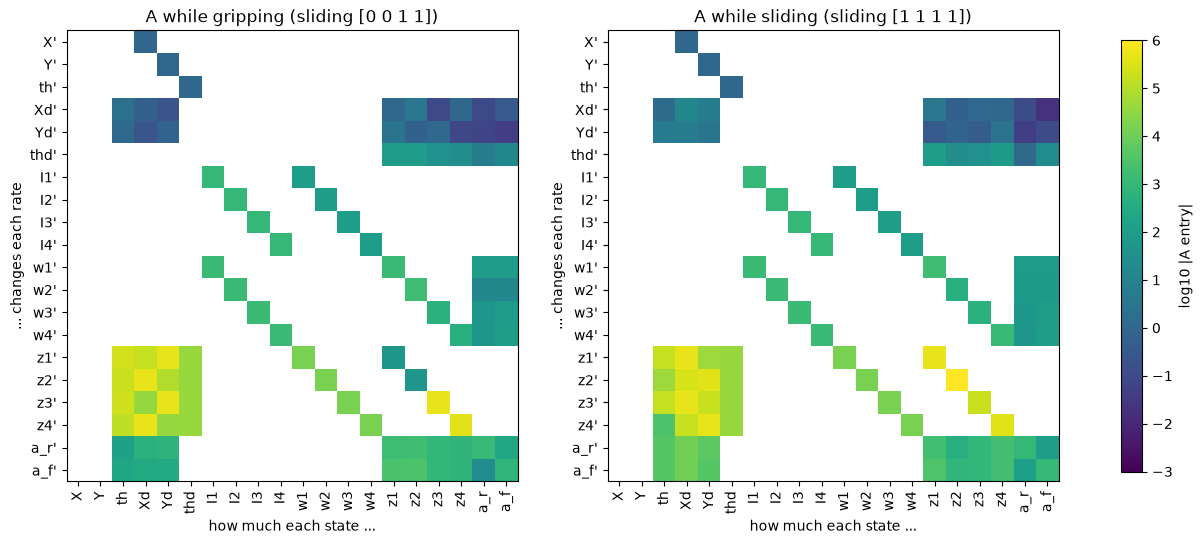

In [93]:
# Step 2 plot: the A matrix while gripping and while sliding (log10 of |entry|; blank = zero)
state_labels = ['X', 'Y', 'th', 'Xd', 'Yd', 'thd', 'I1', 'I2', 'I3', 'I4', 'w1', 'w2', 'w3', 'w4', 'z1', 'z2', 'z3', 'z4', 'a_r', 'a_f']
fig, axs = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, (x, u, a_local_past, sliding_flags)) in zip(axs, points.items()):
    bristle_decay = model.get_bristle_decay(x)
    A, B = model.get_continuous_matrices(x, u, bristle_decay)        # loads differentiated, as the MPC uses it
    magnitude = np.where(np.abs(A) > 1e-9, np.log10(np.abs(A) + 1e-300), np.nan)
    image = ax.imshow(magnitude, cmap='viridis', vmin=-3, vmax=6)
    ax.set_xticks(range(len(state_labels))); ax.set_xticklabels(state_labels, rotation=90)
    ax.set_yticks(range(len(state_labels))); ax.set_yticklabels([lbl + "'" for lbl in state_labels])
    ax.set_title(f"A while {name} (sliding {sliding_flags.astype(int)})")
    ax.set_xlabel("how much each state ...") ; ax.set_ylabel("... changes each rate")
fig.colorbar(image, ax=axs, label="log10 |A entry|", shrink=0.8)
plt.show()


## Step 3 check: the 20 ms model, 0.4 s ahead

From the plant's own states (noise off), each model predicts 0.4 s ahead (20 controller steps) with the voltages the plant actually got, and the predicted position is compared with where the plant went.

* **Linearized:** `get_discrete_matrices` 20 times, as the MPC predicts: each step 20 backward-Euler sub-steps of 1 ms, the Jacobians every 5 ms, the relax rate $d$ every 1 ms.
* **Dana's simple model:** her `OmniRobotNominalModel` (global velocity), 20 steps of $(\mathbf{A}_d, \mathbf{B}_d)$ at the predicted heading.

Three manoeuvres: a 10 V strafe (the wheels slide), a 4 V side-to-side reversal, and random 8 V steps every 0.2 s.


10 V strafe        position error after 0.4 s: linearized median    0.2 mm (worst    2.2) | Dana's simple model median  654.9 mm (worst  660.3)
4 V side-to-side   position error after 0.4 s: linearized median    0.7 mm (worst   12.9) | Dana's simple model median   30.4 mm (worst  203.6)
random 8 V steps   position error after 0.4 s: linearized median    5.4 mm (worst   25.9) | Dana's simple model median   83.4 mm (worst  188.6)


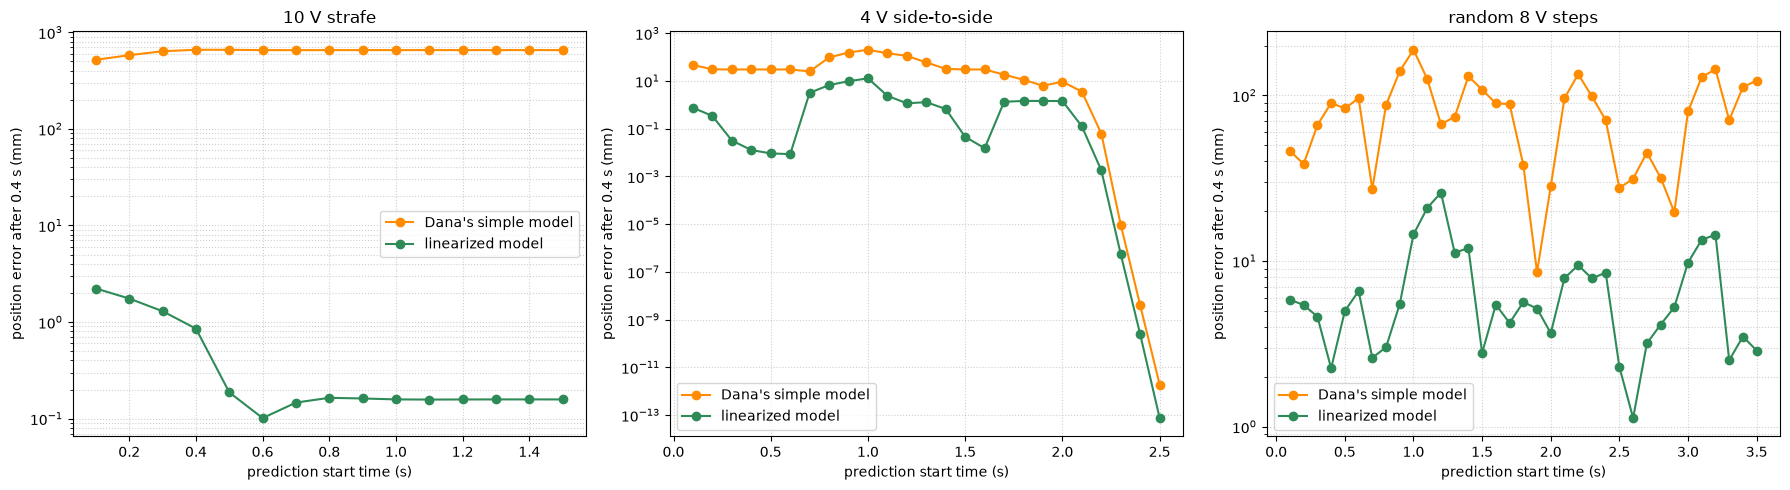

In [94]:
# Step 3 check: 0.4 s predictions against the plant, linearized model and Dana's simple model
pred_params = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
lin_model = OmniRobotLinearizedModel(pred_params)
simple_model = OmniRobotNominalModel(pred_params)
Ts, horizon = 0.02, 20
substeps_per_step = int(round(Ts / pred_params['dt']))
STRAFE = np.array([-1.0, -1.0, 1.0, 1.0])
random_voltages = np.random.default_rng(3).uniform(-8, 8, (20, 4))
manoeuvres = {
    "10 V strafe": (lambda t: 10 * STRAFE, 2.0),
    "4 V side-to-side": (lambda t: -4 * STRAFE * (1.0 if t < 1 else (-1.0 if t < 2 else 0.0)), 3.0),
    "random 8 V steps": (lambda t: random_voltages[min(int(t / 0.2), 19)], 4.0),
}

prediction_results = {}
for name, (V_of_t, duration) in manoeuvres.items():
    plant = OmniRobotSimulationODESolve(pred_params)
    state = OmniRobotStateODESolve()
    states, voltages = [], []
    for k in range(int(round(duration / Ts))):
        V = V_of_t(k * Ts)
        states.append(state)
        voltages.append(V)
        for _ in range(substeps_per_step):
            state = plant.step(state, V)
    states.append(state)

    lin_err, simple_err, starts = [], [], []
    for k in range(5, len(voltages) - horizon, 5):
        # linearized model
        x = lin_model.get_state_from_plant(states[k])
        for j in range(horizon):
            _, _, _, x = lin_model.get_discrete_matrices(x, voltages[k + j], Ts, 20)   # as the MPC: 1 ms sub-steps, Jacobians every 5 ms
        lin_err.append(np.hypot(*(x[:2] - states[k + horizon].pos_global[:2])))
        # Dana's simple model (global velocity)
        xs = np.concatenate((states[k].pos_global, states[k].v_global, states[k].I))
        for j in range(horizon):
            A_d, B_d = simple_model.get_discrete_matrices(xs[2], Ts)
            xs = A_d @ xs + B_d @ voltages[k + j]
        simple_err.append(np.hypot(*(xs[:2] - states[k + horizon].pos_global[:2])))
        starts.append(k * Ts)
    prediction_results[name] = (np.array(starts), 1e3 * np.array(lin_err), 1e3 * np.array(simple_err))
    print(f"{name:18s} position error after 0.4 s: linearized median {np.median(lin_err) * 1e3:6.1f} mm (worst {np.max(lin_err) * 1e3:6.1f}) | "
          f"Dana's simple model median {np.median(simple_err) * 1e3:6.1f} mm (worst {np.max(simple_err) * 1e3:6.1f})")

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (starts, lin_err, simple_err)) in zip(axs, prediction_results.items()):
    ax.plot(starts, simple_err, 'o-', color='darkorange', label="Dana's simple model")
    ax.plot(starts, lin_err, 'o-', color='seagreen', label='linearized model')
    ax.set_yscale('log'); ax.grid(True, which='both', linestyle=':', alpha=0.6)
    ax.set_title(name); ax.set_xlabel("prediction start time (s)"); ax.set_ylabel("position error after 0.4 s (mm)")
    ax.legend()
plt.tight_layout()
plt.show()


## Step 4: the linearized MPC in Dana's runner

Shared helpers for the tests below: the figure eight, the distance off the path, a table, and the plots.

In [95]:
# Helpers for the closed-loop tests: the runner over several controllers, error measures, plots
def figure_eight_path(size, period, laps=2, ramp=0.3, swing=0.3, dt=0.02):
    """Figure eight in Dana's path format (t, pos, vel; global frame): size [m], period per lap [s]."""
    t = np.arange(0.0, laps * period + 1.0, dt)
    rate = 2 * np.pi / period
    phase = rate * (t - ramp * (1 - np.exp(-t / ramp)))
    phase_dot = rate * (1 - np.exp(-t / ramp))
    pos = np.column_stack((size * np.sin(phase), 0.5 * size * np.sin(2 * phase), swing * np.sin(phase)))
    vel = np.column_stack((size * np.cos(phase) * phase_dot, size * np.cos(2 * phase) * phase_dot, swing * np.cos(phase) * phase_dot))
    path = {'t': t, 'pos': pos, 'vel': vel}
    return path


def largest_distance_off_path(robot_xy, reference_xy):
    """Largest distance from the robot's positions to the reference path (the line through its points), ignoring timing."""
    a = reference_xy[:-1]
    ab = reference_xy[1:] - a
    ab_len2 = np.maximum(np.sum(ab**2, axis=1), 1e-12)
    distances = np.zeros(len(robot_xy))
    for i, p in enumerate(robot_xy):
        s = np.clip(np.sum((p - a) * ab, axis=1) / ab_len2, 0.0, 1.0)
        distances[i] = np.min(np.hypot(*(a + s[:, None] * ab - p).T))
    return distances.max()


def run_and_report(title, paths, controllers, params):
    """Run every controller on every path in Dana's runner; print a table; return the results."""
    results = {}
    print(f"{title}\n{'Path':28s} {'Controller':13s} {'Off path (cm)':>13s} {'Max error (cm)':>14s} {'RMS (cm)':>9s} {'Final (cm)':>10s} {'Heading (deg)':>13s} {'Sliding (%)':>11s} {'ms/step':>8s}")
    for path_name, path in paths.items():
        for controller in controllers:
            res = execute_simulation(params, controller, path)
            results[(path_name, controller)] = res
            off_path = largest_distance_off_path(res['pos'][:, :2], res['pos_ref'][:, :2])
            sliding = 100 * np.mean(np.any(np.abs(res['vs']) > 5e-3, axis=1))
            print(f"{path_name:28s} {controller:13s} {100 * off_path:13.1f} {100 * res['dist_err'].max():14.1f} {100 * np.sqrt(np.mean(res['dist_err']**2)):9.1f} "
                  f"{100 * res['dist_err'][-1]:10.1f} {np.degrees(res['th_err'].max()):13.1f} {sliding:11.1f} {1000 * res['elapsed'] / len(res['t']):8.1f}", flush=True)
    return results


def heading_arrows(ax, xy, theta, color, length, count=12, alpha=0.8):
    """Arrows along a path showing which way the robot faces: forward is +y of the robot, so the direction is
    R(theta) [0, 1] = (-sin theta, cos theta) (as in Dana's plots). count arrows, evenly spaced in time."""
    every = max(1, len(xy) // count)
    idx = np.arange(0, len(xy), every)
    ax.quiver(xy[idx, 0], xy[idx, 1], -np.sin(theta[idx]) * length, np.cos(theta[idx]) * length,
              color=color, angles='xy', scale_units='xy', scale=1.0, width=0.004, alpha=alpha)


def plot_paths(results, paths, controllers, columns=3):
    """X-Y paths of every controller, one subplot per path, with heading arrows (grey: the reference's heading)."""
    rows = int(np.ceil(len(paths) / columns))
    fig, axs = plt.subplots(rows, columns, figsize=(6 * columns, 6 * rows), squeeze=False)
    for ax, path_name in zip(axs.ravel(), paths):
        ref = results[(path_name, controllers[0])]['pos_ref']
        size = max(np.ptp(ref[:, 0]), np.ptp(ref[:, 1]), 0.2)       # arrow length: 8% of the path's size
        ax.plot(ref[:, 0], ref[:, 1], 'k:', lw=1.8, label='Reference')
        heading_arrows(ax, ref[:, :2], ref[:, 2], 'grey', 0.08 * size, alpha=0.6)
        for controller in controllers:
            pos = results[(path_name, controller)]['pos']
            ax.plot(pos[:, 0], pos[:, 1], color=controller_colors[controller], lw=2.0, label=controller)
            heading_arrows(ax, pos[:, :2], pos[:, 2], controller_colors[controller], 0.08 * size)
        ax.set_aspect('equal', 'datalim'); ax.grid(True, linestyle=':', alpha=0.6)
        ax.set_title(path_name); ax.set_xlabel('Global X (m)'); ax.set_ylabel('Global Y (m)'); ax.legend(loc='best', fontsize='small')
    for ax in axs.ravel()[len(paths):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def plot_errors(results, paths, controllers, columns=3):
    """For each path: Dana's position error over time (top) and the heading error over time (below it)."""
    rows = int(np.ceil(len(paths) / columns))
    fig, axs = plt.subplots(2 * rows, columns, figsize=(6 * columns, 7 * rows), squeeze=False)
    for n, path_name in enumerate(paths):
        ax_pos = axs[2 * (n // columns), n % columns]
        ax_head = axs[2 * (n // columns) + 1, n % columns]
        for controller in controllers:
            res = results[(path_name, controller)]
            ax_pos.plot(res['t'], 100 * res['dist_err'], color=controller_colors[controller], lw=1.6, label=controller)
            ax_head.plot(res['t'], np.degrees(res['th_err']), color=controller_colors[controller], lw=1.6, label=controller)
        ax_pos.grid(True, linestyle=':', alpha=0.6); ax_pos.set_title(path_name)
        ax_pos.set_ylabel('Position error (cm)'); ax_pos.legend(loc='best', fontsize='small')
        ax_head.grid(True, linestyle=':', alpha=0.6)
        ax_head.set_xlabel('Time (s)'); ax_head.set_ylabel('Heading error (deg)')
    for n in range(len(paths), rows * columns):
        axs[2 * (n // columns), n % columns].axis('off')
        axs[2 * (n // columns) + 1, n % columns].axis('off')
    plt.tight_layout()
    plt.show()


analysis_params = simulation_parameters.copy()
path_generator = PathGenerator(dt=0.02)


## Step 4: Dana's benchmark

Her two paths, (0, 0, 0) to (3, 3, π/4) in 8 s and in 4 s, with all four controllers. The 4 s path needs more wheel speed than 12 V gives, so every controller falls behind on it.


Dana's benchmark
Path                         Controller    Off path (cm) Max error (cm)  RMS (cm) Final (cm) Heading (deg) Sliding (%)  ms/step
Dana 8 s                     pid                     3.3           59.6      36.4        0.4           3.3         0.0      0.1
Dana 8 s                     mpc                     2.4            8.8       6.4        5.9           0.6         0.0      6.7
Dana 8 s                     mpc_lin                 0.5            2.0       1.3        1.2           0.2         0.0     10.2
Dana 8 s                     mpc_lin_obs             0.5            2.0       1.3        1.1           0.2         0.0      9.9
Dana 4 s                     pid                     7.5          139.0      92.0       44.6          28.6        46.0      0.1
Dana 4 s                     mpc                    11.4           61.3      36.1       32.7          24.2        53.5      6.2
Dana 4 s                     mpc_lin                 2.4           55.8      30.4      

<string>:214: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.


Dana 4 s                     mpc_lin_obs             2.6           56.0      30.5       22.0           9.4        41.5     10.0


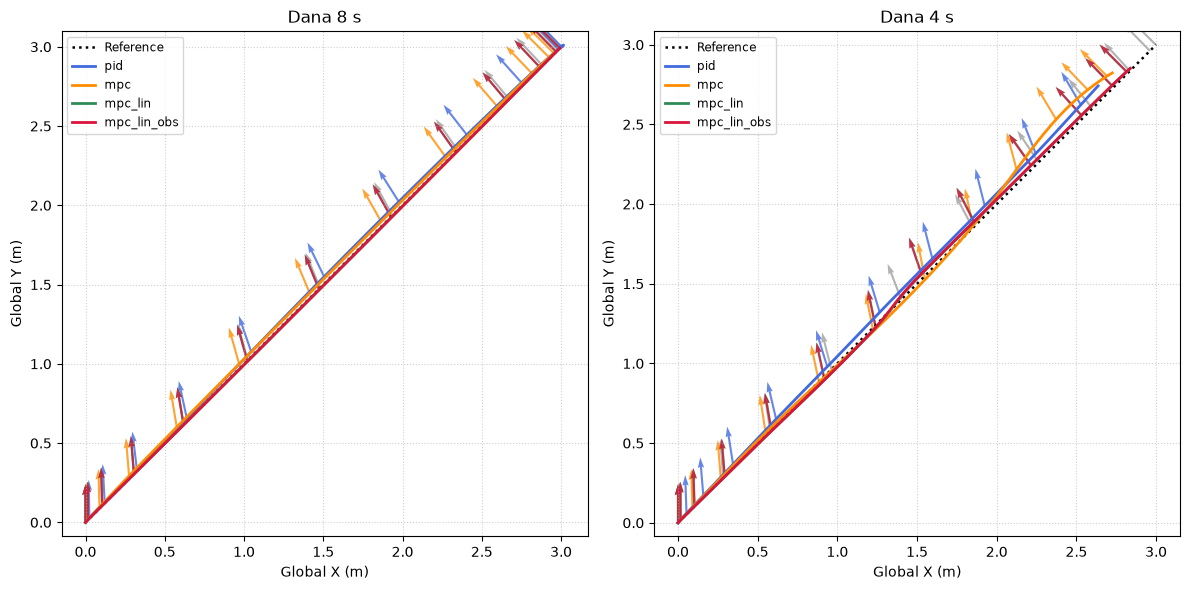

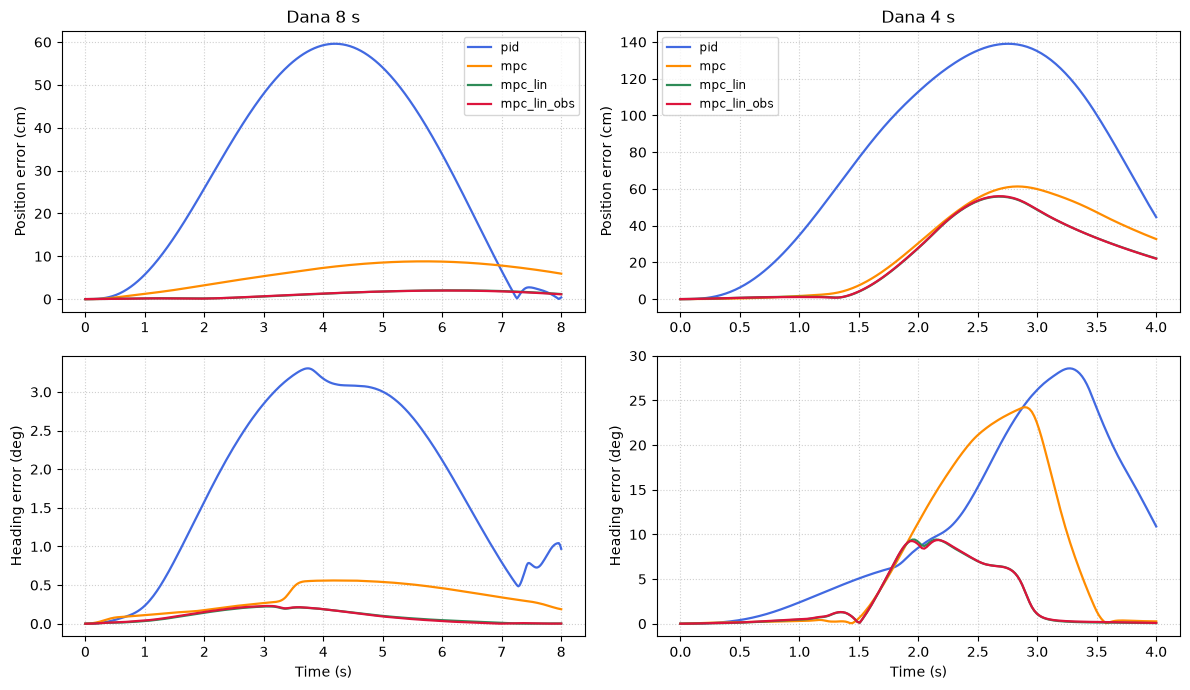

In [96]:
# Dana's benchmark: her two paths, all four controllers
benchmark_paths = {
    "Dana 8 s": path_generator.generate_coupled_segment(np.zeros(3), np.array([3.0, 3.0, np.pi / 4]), duration=8.0),
    "Dana 4 s": path_generator.generate_coupled_segment(np.zeros(3), np.array([3.0, 3.0, np.pi / 4]), duration=4.0),
}
benchmark_controllers = ['pid', 'mpc', 'mpc_lin', 'mpc_lin_obs']
benchmark_results = run_and_report("Dana's benchmark", benchmark_paths, benchmark_controllers, analysis_params)
plot_paths(benchmark_results, benchmark_paths, benchmark_controllers, columns=2)
plot_errors(benchmark_results, benchmark_paths, benchmark_controllers, columns=2)


## Step 4: test motions (attainable)

From the main analysis file, a shorter set: the quick hops (Dana's generator, ±0.5 m, 1.25 s per segment) and the 0.4 m figure eight twice: 3 s per lap, which slides, and 3.4 s per lap, on the edge between rolling and sliding (the time in a figure eight's name is per lap; each runs two laps plus a 1 s ramp).


Test motions
Path                         Controller    Off path (cm) Max error (cm)  RMS (cm) Final (cm) Heading (deg) Sliding (%)  ms/step
Quick hops (1.25 s)          pid                     5.1           44.1      24.8       29.2          44.2         0.0      0.1
Quick hops (1.25 s)          mpc                     3.4            5.6       3.1        5.4           2.6         2.2      6.3
Quick hops (1.25 s)          mpc_lin                 1.5            2.9       1.8        2.3           2.4         2.5     10.2
Quick hops (1.25 s)          mpc_lin_obs             1.5            2.8       1.7        2.3           2.3         2.5      9.7
Figure eight 0.4 m (3 s)     pid                    15.3           47.3      32.4       34.4          13.1         0.0      0.1
Figure eight 0.4 m (3 s)     mpc                     4.5            4.7       3.4        4.7           1.4         7.1      6.3
Figure eight 0.4 m (3 s)     mpc_lin                 2.3            2.7       2.1        1.

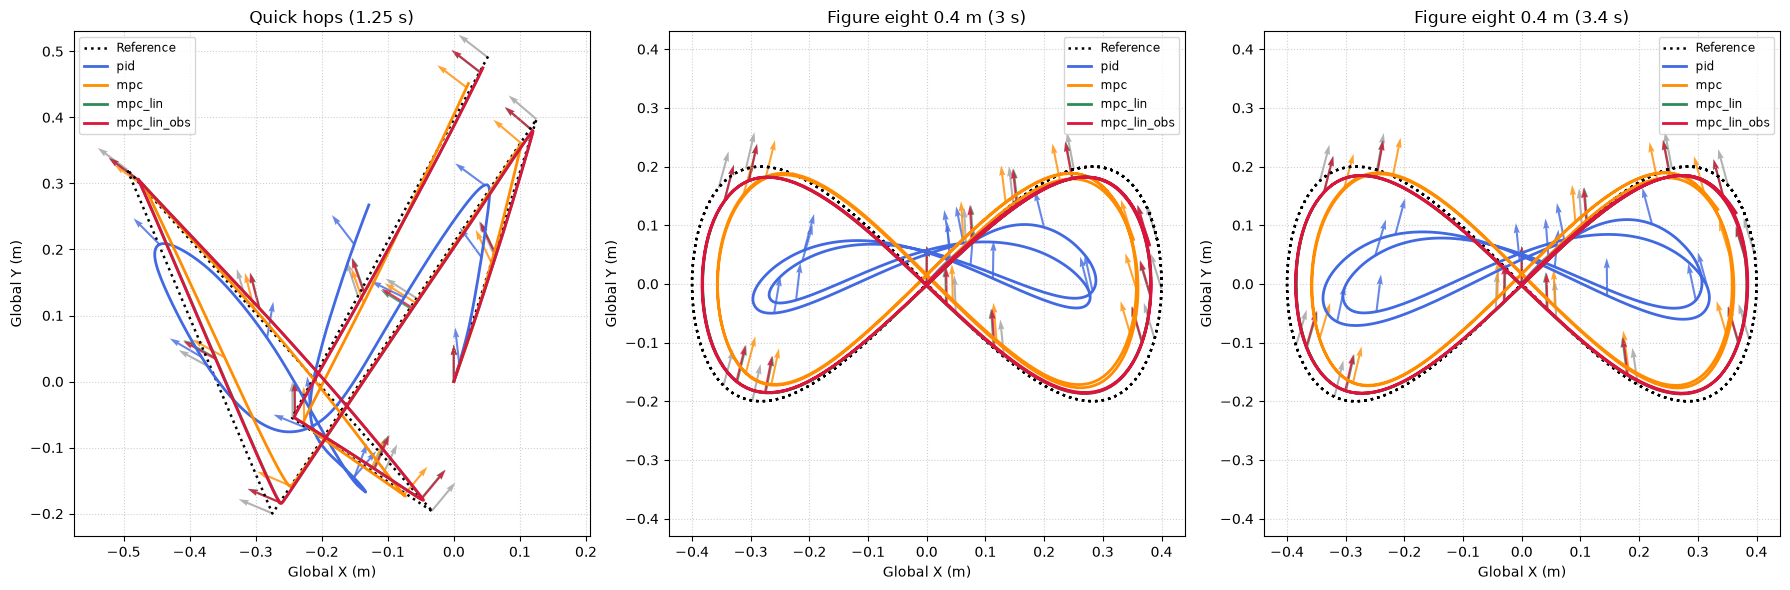

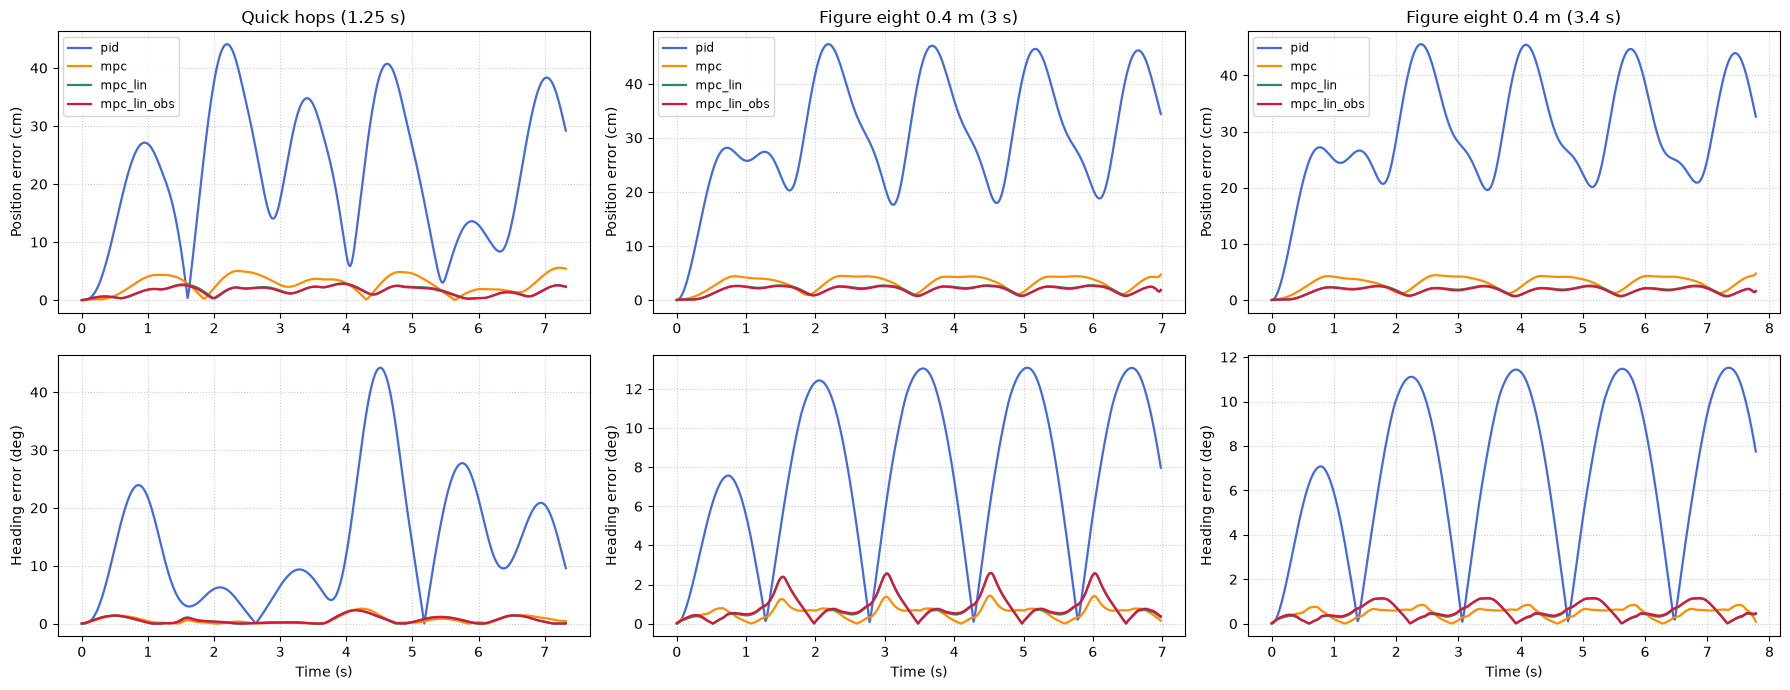

In [97]:
# Test motions: quick hops and figure eights, PID / simple MPC / linearized MPC
small_area = {'x_min': -0.5, 'x_max': 0.5, 'y_min': -0.5, 'y_max': 0.5, 'theta_min': -np.pi / 2, 'theta_max': np.pi / 2}
motion_paths = {
    "Quick hops (1.25 s)": path_generator.generate_random_sequence(num_segments=6, workspace_bounds=small_area, segment_duration=1.25, random_seed=7),
    "Figure eight 0.4 m (3 s)": figure_eight_path(0.4, 3.0),
    "Figure eight 0.4 m (3.4 s)": figure_eight_path(0.4, 3.4),     # the same eight with more time per lap: on the edge between rolling and sliding
}
motion_controllers = ['pid', 'mpc', 'mpc_lin', 'mpc_lin_obs']
motion_results = run_and_report("Test motions", motion_paths, motion_controllers, analysis_params)
plot_paths(motion_results, motion_paths, motion_controllers)
plot_errors(motion_results, motion_paths, motion_controllers)


## Step 4: Dana's turning test

(0, 0, 0) to (3, 3, π/2) in 5 s (95% of the wheel limit) and to (3, 3, π) in 6 s (at the limit).


Turning test
Path                         Controller    Off path (cm) Max error (cm)  RMS (cm) Final (cm) Heading (deg) Sliding (%)  ms/step
to (3, 3, pi/2) in 5 s       pid                    12.3          101.4      64.0        6.5          17.6         1.2      0.1
to (3, 3, pi/2) in 5 s       mpc                     2.2           10.2       7.0        7.1           1.0         0.0      6.3
to (3, 3, pi/2) in 5 s       mpc_lin                 0.7            3.8       2.1        2.7           0.5         0.0      9.9
to (3, 3, pi/2) in 5 s       mpc_lin_obs             0.6            3.6       2.1        2.5           0.5         0.0      9.6
to (3, 3, pi) in 6 s         pid                    20.3           88.8      55.5        4.5          20.8        10.3      0.1
to (3, 3, pi) in 6 s         mpc                     2.4            9.5       6.3        6.1           1.4         0.0      6.2
to (3, 3, pi) in 6 s         mpc_lin                 0.6            3.3       2.2        2.

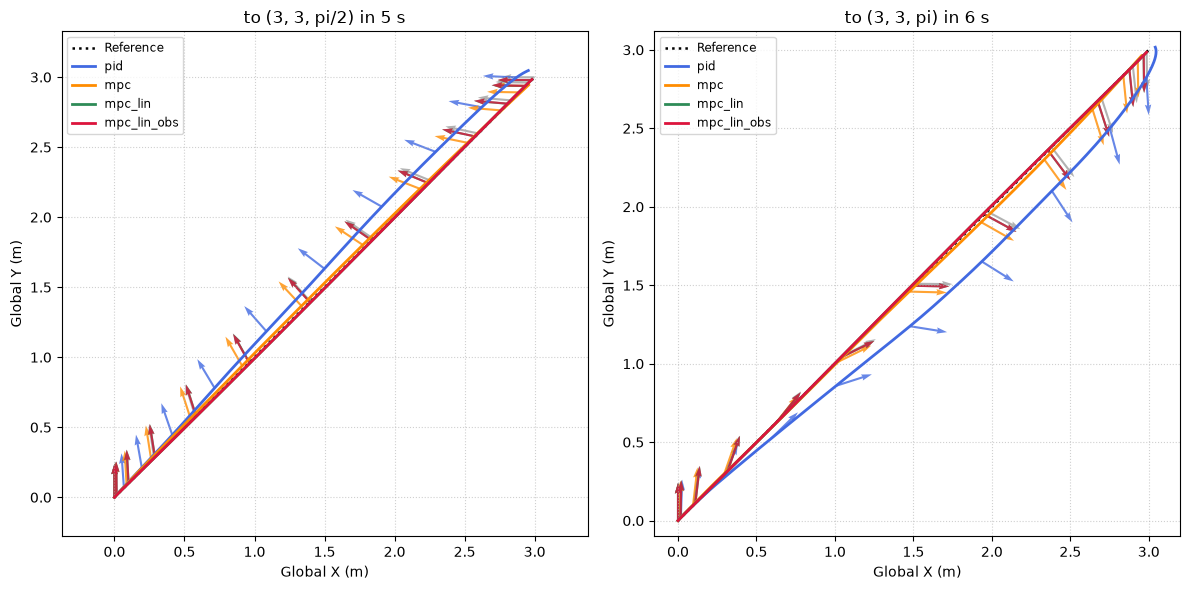

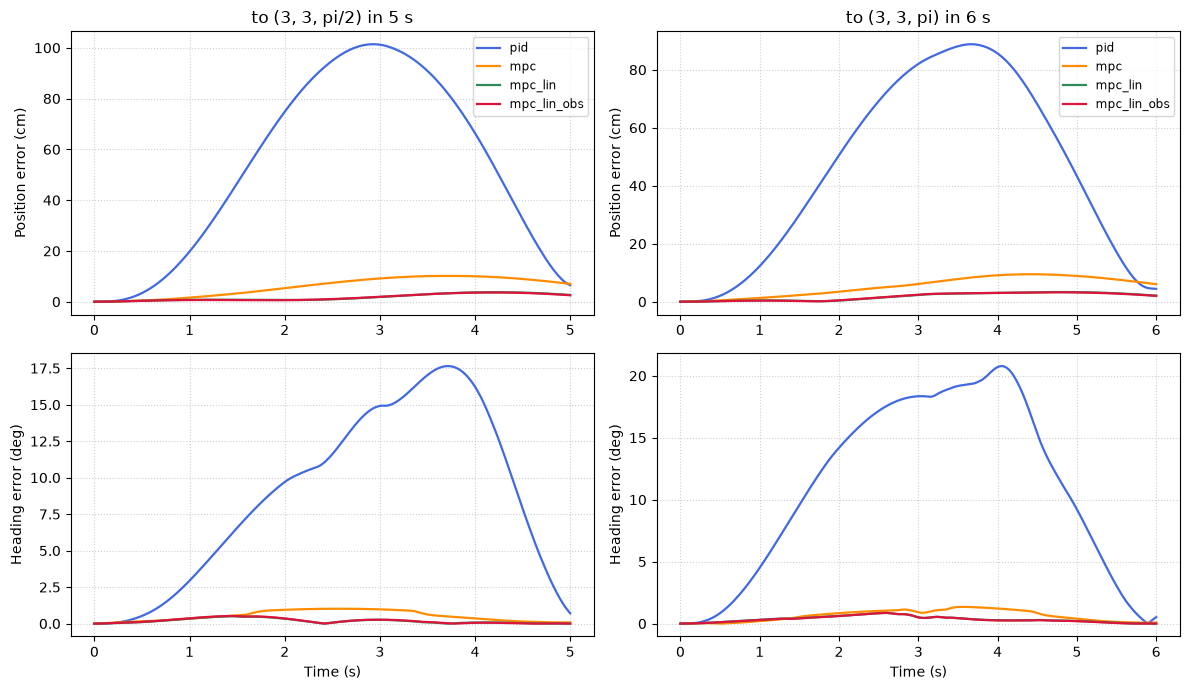

In [98]:
# Dana's turning test: the two hardest attainable cases
turn_paths = {
    "to (3, 3, pi/2) in 5 s": path_generator.generate_coupled_segment(np.zeros(3), np.array([3.0, 3.0, np.pi / 2]), duration=5.0),
    "to (3, 3, pi) in 6 s": path_generator.generate_coupled_segment(np.zeros(3), np.array([3.0, 3.0, np.pi]), duration=6.0),
}
turn_controllers = ['pid', 'mpc', 'mpc_lin', 'mpc_lin_obs']
turn_results = run_and_report("Turning test", turn_paths, turn_controllers, analysis_params)
plot_paths(turn_results, turn_paths, turn_controllers, columns=2)
plot_errors(turn_results, turn_paths, turn_controllers, columns=2)


## Observer, step 1: its estimate against the plant's true state

The plant runs with set voltages (noise on, as in `simulation_parameters`). The observer gets only what the robot measures: the wheel speeds and currents every 1 ms, and the camera pose every 20 ms. Its estimate is compared with the plant's true state at every 20 ms controller step (when the MPC would read it).

Baseline: the velocity Dana's MPC uses, her `PoseVelocityEstimator` (the pose difference over the last 20 ms).

Three runs: a 6 V strafe reversed at 0.5 s (the wheels slide), a 4 V side-to-side, and random 8 V steps every 0.2 s.


Run                               velocity error, observer  velocity error, Dana 20 ms  z error, observer  pose error
6 V strafe, reversed at 0.5 s          0.6 mm/s (worst     14)      23.6 mm/s (worst     49)    0.049 (worst 0.183)      0.00 mm
4 V side-to-side                       0.0 mm/s (worst     11)       5.7 mm/s (worst     62)    0.020 (worst 0.165)      0.00 mm
random 8 V steps                       1.4 mm/s (worst     16)      23.4 mm/s (worst     72)    0.050 (worst 0.968)      0.00 mm


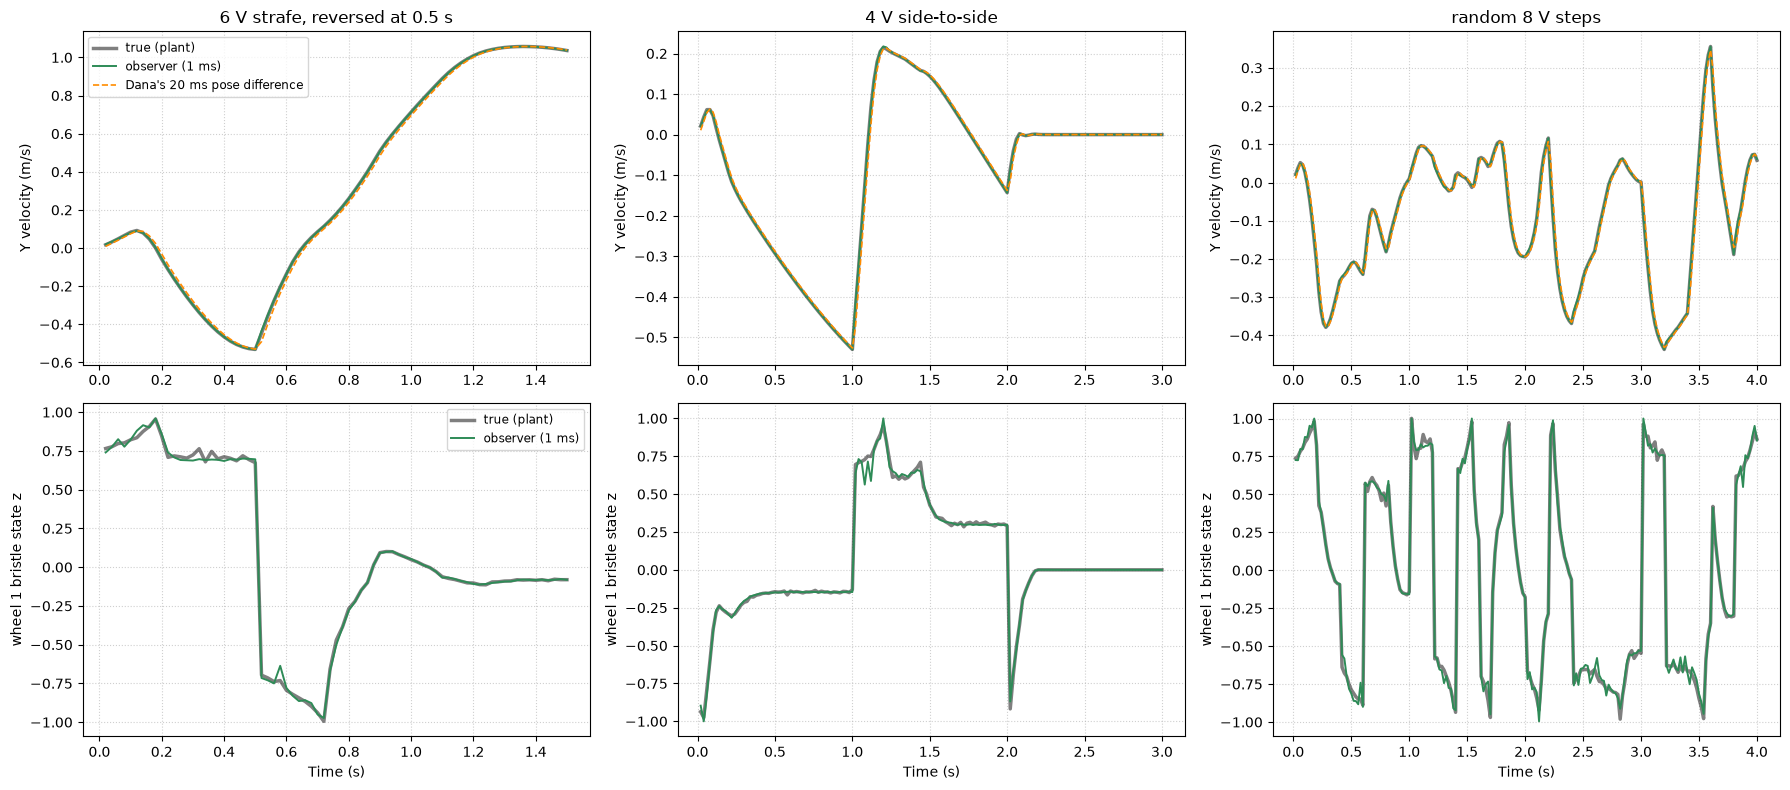

In [99]:
# Observer step 1: the observer's estimate against the plant's true state, open loop
observer_params = simulation_parameters.copy()
camera_every = int(round(0.02 / observer_params['dt']))          # a camera frame every 20 ms
STRAFE = np.array([-1.0, -1.0, 1.0, 1.0])
observer_random_V = np.random.default_rng(3).uniform(-8, 8, (20, 4))
observer_runs = {
    "6 V strafe, reversed at 0.5 s": (lambda t: 6 * STRAFE * (1.0 if t < 0.5 else -1.0), 1.5),
    "4 V side-to-side": (lambda t: -4 * STRAFE * (1.0 if t < 1 else (-1.0 if t < 2 else 0.0)), 3.0),
    "random 8 V steps": (lambda t: observer_random_V[min(int(t / 0.2), 19)], 4.0),
}

observer_traces = {}
print(f"{'Run':32s} {'velocity error, observer':>25s} {'velocity error, Dana 20 ms':>27s} {'z error, observer':>18s} {'pose error':>11s}")
for run_name, (V_of_t, duration) in observer_runs.items():
    plant = OmniRobotSimulationODESolve(observer_params, random_seed=42)
    state = OmniRobotStateODESolve()
    observer = RobotObserver1ms(observer_params)
    dana_velocity = PoseVelocityEstimator(dt=0.02)
    dana_velocity.estimate(state.pos_global)
    trace = {'t': [], 'v_true': [], 'v_obs': [], 'v_dana': [], 'z_true': [], 'z_obs': []}
    steps = int(round(duration / observer_params['dt']))
    for k in range(steps):
        V = V_of_t(k * observer_params['dt'])
        state = plant.step(state, V)
        camera_pose = state.pos_global.copy() if (k + 1) % camera_every == 0 else None
        observer.update(state.V_actual, state.omega.copy(), state.I.copy(), camera_pose)
        if camera_pose is not None:                                 # a controller step: compare
            trace['t'].append((k + 1) * observer_params['dt'])
            trace['v_true'].append(state.v_global.copy())
            x_hat = observer.estimate()
            trace['v_obs'].append(x_hat[observer.model.VELOCITY])
            trace['v_dana'].append(dana_velocity.estimate(camera_pose))
            trace['z_true'].append(state.z.copy())
            trace['z_obs'].append(x_hat[observer.model.BRISTLES])
            pose_error = np.hypot(*(x_hat[:2] - state.pos_global[:2]))
    trace = {key: np.array(value) for key, value in trace.items()}
    observer_traces[run_name] = trace
    v_err_obs = np.hypot(*(trace['v_obs'][:, :2] - trace['v_true'][:, :2]).T)
    v_err_dana = np.hypot(*(trace['v_dana'][:, :2] - trace['v_true'][:, :2]).T)
    z_err = np.abs(trace['z_obs'] - trace['z_true']).max(axis=1)
    print(f"{run_name:32s} {1000 * np.median(v_err_obs):9.1f} mm/s (worst {1000 * v_err_obs.max():6.0f}) "
          f"{1000 * np.median(v_err_dana):9.1f} mm/s (worst {1000 * v_err_dana.max():6.0f})   "
          f"{np.median(z_err):6.3f} (worst {z_err.max():.3f})   {1000 * pose_error:7.2f} mm")

# Plot: forward (Y) velocity and wheel 1's bristle state, true against estimated
fig, axs = plt.subplots(2, len(observer_runs), figsize=(18, 8))
for column, (run_name, trace) in enumerate(observer_traces.items()):
    axs[0, column].plot(trace['t'], trace['v_true'][:, 1], 'k-', lw=2.5, alpha=0.5, label='true (plant)')
    axs[0, column].plot(trace['t'], trace['v_obs'][:, 1], color='seagreen', lw=1.4, label='observer (1 ms)')
    axs[0, column].plot(trace['t'], trace['v_dana'][:, 1], color='darkorange', lw=1.2, ls='--', label="Dana's 20 ms pose difference")
    axs[0, column].set_title(run_name); axs[0, column].set_ylabel('Y velocity (m/s)'); axs[0, column].grid(True, linestyle=':', alpha=0.6)
    axs[1, column].plot(trace['t'], trace['z_true'][:, 0], 'k-', lw=2.5, alpha=0.5, label='true (plant)')
    axs[1, column].plot(trace['t'], trace['z_obs'][:, 0], color='seagreen', lw=1.4, label='observer (1 ms)')
    axs[1, column].set_ylabel('wheel 1 bristle state z'); axs[1, column].set_xlabel('Time (s)'); axs[1, column].grid(True, linestyle=':', alpha=0.6)
axs[0, 0].legend(fontsize='small'); axs[1, 0].legend(fontsize='small')
plt.tight_layout()
plt.show()
